# PCA from Scratch: Seeing 13 Wine Measurements in 2D

**Unsupervised learning: Principal Component Analysis (PCA)**

In this notebook we build PCA **by hand with NumPy**, one maths step at a time, and then check our answer against scikit-learn's built-in `PCA`.

**What you will learn**
- why we scale the data before PCA
- what a covariance matrix tells us
- what eigenvectors and eigenvalues are, and why they give the "best directions"
- how to squeeze 13 columns into 2 and still see the structure in the data
- how to read what each principal component means

## 1. Problem statement

A lab analysed **178 wines** grown in the same region of Italy. The wines come from **3 different grape types** (cultivars). For every wine they measured **13 chemical properties**: alcohol, colour intensity, flavanoids and so on.

13 numbers per wine means every wine is a point in **13-dimensional space**. We can draw 2 dimensions (3 at most), but not 13.

**Question:** can we replace the 13 numbers with just **2 new numbers** that keep most of the information, and then *see* the wines on a normal 2D plot?

That is exactly what **PCA** does. PCA is **unsupervised**: it never looks at the grape type. We use the grape type only at the end, to colour the plot and check whether PCA found real structure.

## 2. Approach

| Step | What we do | Maths | Result |
|---|---|---|---|
| 1 | Scale every column | $z = \dfrac{x - \bar{x}}{s}$ | scaled table $Z$ (178 × 13) |
| 2 | Covariance matrix | $C = \dfrac{1}{n-1} Z^\top Z$ | $C$ (13 × 13) |
| 3 | Eigenvectors and eigenvalues | $C v = \lambda v$ | 13 directions (the PCs) and their spreads |
| 4 | Information kept by each PC | $\lambda_k \,/\, \sum \lambda$ | explained variance |
| 5 | Keep the top 2 PCs and project | $T = Z W$ | 2 numbers per wine (178 × 2) |

Then we check the result against scikit-learn's `PCA` and interpret what the two new axes mean.

## 3. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

## 4. The dataset

The Wine dataset from the UCI Machine Learning Repository: a chemical analysis of wines from 3 grape types.

- **Rows:** 178 wines
- **Columns:** 13 chemical measurements
- **Label:** `grape` (A, B or C), used **only** to colour plots

### 4.1 Load the data from Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
DATA_PATH = "/content/drive/MyDrive/workshop/pca/"

df = pd.read_csv(DATA_PATH + "wine.csv")
print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,grape
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,A
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,A
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,A
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,A
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,A


In [ ]:
df["grape"].value_counts().sort_index()

,count
grape,
A,59
B,71
C,48


### 4.2 Is the data clean?

In [ ]:
print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print("Numeric columns:", df.select_dtypes("number").shape[1], "of 13 measurements")

Missing values : 0
Duplicate rows : 0
Numeric columns: 13 of 13 measurements


The data is already clean: no missing values, no duplicate rows, and all 13 measurements are numbers.
A few values are extreme (for example, the highest magnesium is 162 against an average of about 100), but they are plausible lab measurements rather than typing errors, so we keep them. No cleaning is needed.

### 4.3 Features and label

In [ ]:
X = df.drop(columns="grape")   # 13 measurements (used by PCA)
y = df["grape"]                # grape type (used only to colour plots)

n, p = X.shape
print(n, "wines,", p, "measurements")

178 wines, 13 measurements


## 5. Explore the data (EDA)

### 5.1 The columns live on very different scales

In [ ]:
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Look at `proline` (from 278 up to 1680) versus `hue` (around 1). PCA hunts for the directions with the **most spread (variance)**.
Without scaling, proline's variance (about 99,000) would swamp hue's (about 0.05), and PCA would simply rediscover "proline".
So we must scale first (Step 1).

### 5.2 Many columns repeat each other

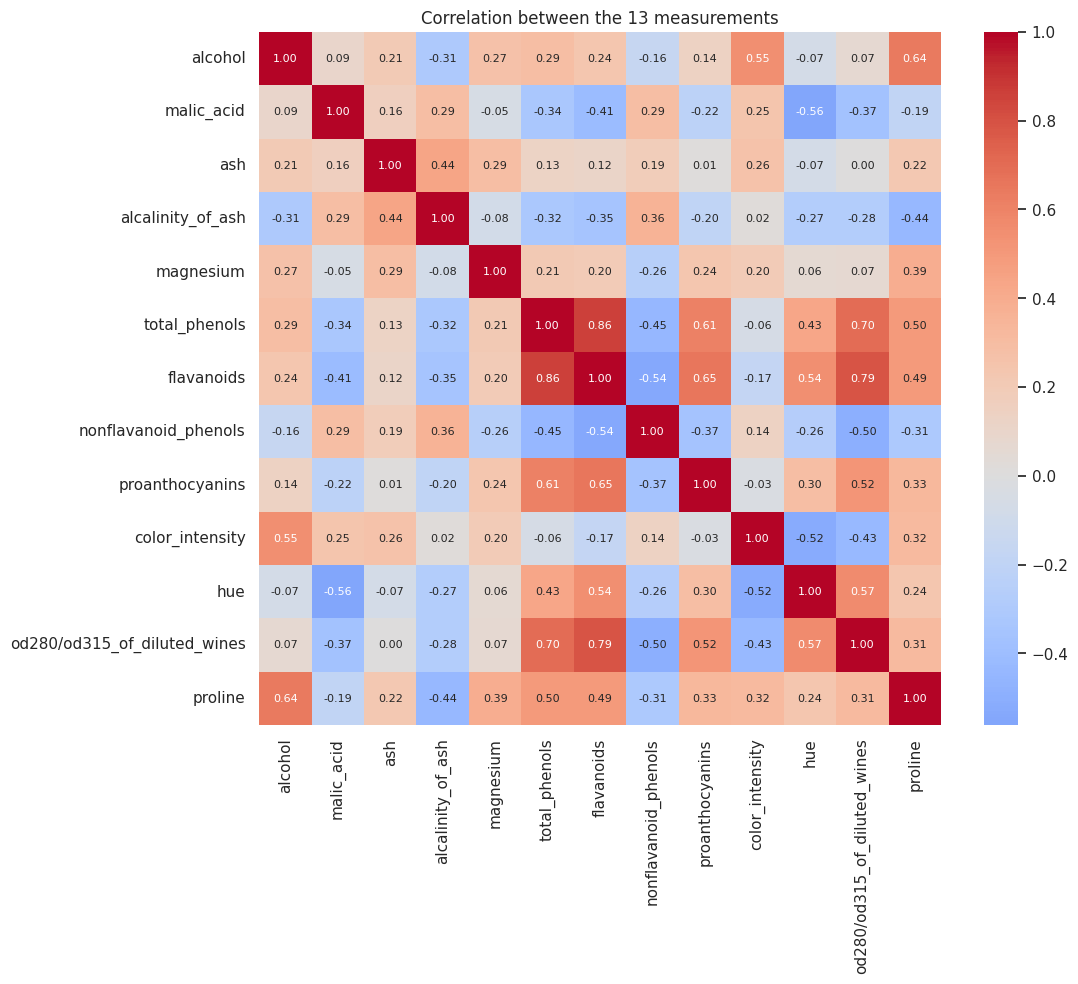

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation between the 13 measurements")
plt.show()

Some pairs are strongly related, for example `total_phenols` and `flavanoids` (**0.86**), or `flavanoids` and `od280/od315_of_diluted_wines` (**0.79**).

Correlated columns carry **overlapping information**. PCA merges overlapping columns into one new column, and that is why fewer numbers can still hold most of the information.

## 6. Step 1: Scale every column

For every column $j$ and every wine $i$:

$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$

where $\bar{x}_j$ is the column mean and $s_j$ is its standard deviation.
After scaling, every column has **mean 0** and **standard deviation 1**, so all 13 measurements get an equal vote.

In [ ]:
Z = (X - X.mean()) / X.std()

print("Every column has mean 0:", np.allclose(Z.mean(), 0))
print("Every column has std 1: ", np.allclose(Z.std(), 1))
Z.head().round(2)

Every column has mean 0: True
Every column has std 1:  True


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.51,-0.56,0.23,-1.17,1.91,0.81,1.03,-0.66,1.22,0.25,0.36,1.84,1.01
1,0.25,-0.50,-0.83,-2.48,0.02,0.57,0.73,-0.82,-0.54,-0.29,0.40,1.11,0.96
2,0.20,0.02,1.11,-0.27,0.09,0.81,1.21,-0.50,2.13,0.27,0.32,0.79,1.39
3,1.69,-0.35,0.49,-0.81,0.93,2.48,1.46,-0.98,1.03,1.18,-0.43,1.18,2.33
4,0.29,0.23,1.84,0.45,1.28,0.81,0.66,0.23,0.40,-0.32,0.36,0.45,-0.04


## 7. Step 2: Covariance matrix

The covariance between columns $j$ and $k$ is

$$C_{jk} = \frac{1}{n-1}\sum_{i=1}^{n} z_{ij}\, z_{ik}$$

- big positive → the two columns go up together
- big negative → one goes up when the other goes down
- close to 0 → no straight-line relation

All 13 × 13 pairs at once, in matrix form:

$$C = \frac{1}{n-1}\, Z^\top Z$$

In [ ]:
C = Z.T @ Z / (n - 1)

print(C.shape)
print("Equal to the correlation matrix:", np.allclose(C, X.corr()))

(13, 13)
Equal to the correlation matrix: True


For **scaled** data the covariance matrix is exactly the correlation matrix we plotted in 5.2.
Its diagonal is all 1s (each scaled column has variance 1), so the **total variance is 13**.

## 8. Step 3a: What is a principal component? (see it with 2 columns)

Before using all 13 columns, let's build intuition with two strongly correlated ones: `total_phenols` and `flavanoids`.

Pick any direction, a vector $u$ of length 1. Project every wine onto that line (its "shadow" on the line): $t_i = z_i \cdot u$.
The variance of those shadows is

$$\text{Var}(Zu) = u^\top C\, u$$

PCA looks for the direction $u$ whose shadows have the **largest variance**. Let's simply try every angle from 0° to 179°:

In [ ]:
two = Z[["total_phenols", "flavanoids"]].to_numpy()

angles = np.arange(180)                                            # 0°, 1°, ..., 179°
spread = []
for a in angles:
    u = np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])   # direction of length 1
    spread.append(np.var(two @ u, ddof=1))                         # variance of the shadows
spread = np.array(spread)

best = angles[spread.argmax()]
print(f"Best angle: {best}°   largest spread: {spread.max():.3f}")

Best angle: 45°   largest spread: 1.865


Now compare with the eigenvectors of the 2 × 2 covariance matrix of these two columns:

In [ ]:
C2 = C.loc[["total_phenols", "flavanoids"], ["total_phenols", "flavanoids"]]
vals2, vecs2 = np.linalg.eigh(C2)       # eigh returns the smallest eigenvalue first
v = vecs2[:, -1]                        # eigenvector with the biggest eigenvalue

print("Eigenvalues:", vals2.round(3))
print(f"Angle of the top eigenvector: {np.degrees(np.arctan2(v[1], v[0])) % 180:.0f}°")

Eigenvalues: [0.135 1.865]
Angle of the top eigenvector: 45°


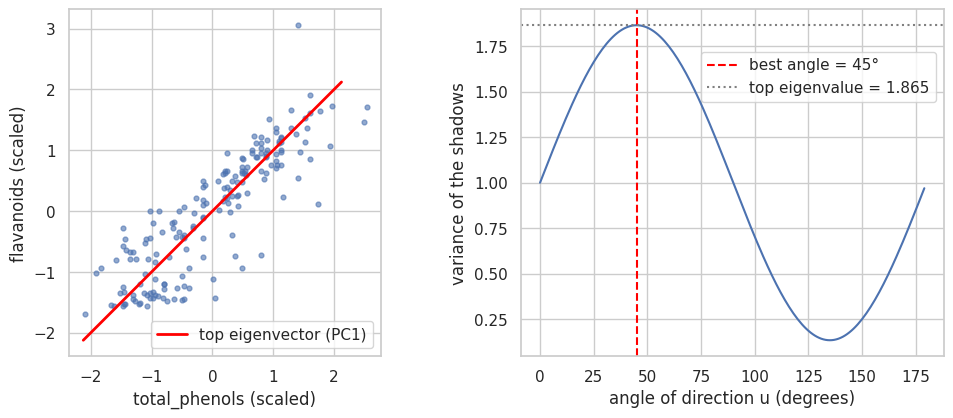

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].scatter(two[:, 0], two[:, 1], s=12, alpha=0.6)
ax[0].plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], color="red", lw=2, label="top eigenvector (PC1)")
ax[0].set_xlabel("total_phenols (scaled)")
ax[0].set_ylabel("flavanoids (scaled)")
ax[0].set_aspect("equal")
ax[0].legend()

ax[1].plot(angles, spread)
ax[1].axvline(best, color="red", ls="--", label=f"best angle = {best}°")
ax[1].axhline(vals2[-1], color="gray", ls=":", label=f"top eigenvalue = {vals2[-1]:.3f}")
ax[1].set_xlabel("angle of direction u (degrees)")
ax[1].set_ylabel("variance of the shadows")
ax[1].legend(loc="upper right", bbox_to_anchor=(1, 0.9))
plt.show()

**What we just saw**
- The direction with the biggest spread is **exactly the top eigenvector** of the covariance matrix (45° here).
- The biggest spread **equals the top eigenvalue** (1.865).
- That single direction holds 1.865 / 2 = **93%** of the total spread of the two columns, so one number can replace two.

**Why eigenvectors?** We want the largest $u^\top C u$ while keeping $u^\top u = 1$. Using a Lagrange multiplier $\lambda$:

$$L = u^\top C u - \lambda\,(u^\top u - 1) \qquad\Rightarrow\qquad \frac{\partial L}{\partial u} = 2Cu - 2\lambda u = 0 \qquad\Rightarrow\qquad C u = \lambda u$$

So the best direction is an eigenvector, and its variance is $u^\top C u = \lambda\, u^\top u = \lambda$. The biggest eigenvalue gives the best direction.

For a 2 × 2 correlation matrix $\begin{pmatrix} 1 & r \\ r & 1 \end{pmatrix}$ the eigenvalues are $1 \pm r$.
Here $r = 0.865$, so $\lambda = 1.865$ and $0.135$, exactly what NumPy printed.

## 9. Step 3b: Eigenvectors and eigenvalues of all 13 columns

Now the same idea in 13 dimensions. We solve

$$C\,v = \lambda\,v$$

- each **eigenvector** $v$ is a direction in 13-D space: a recipe of 13 weights, one per original column. This is a **principal component (PC)**.
- its **eigenvalue** $\lambda$ is the variance of the data along that direction.
- the 13 eigenvectors are perpendicular to each other, so the PCs are uncorrelated.

`np.linalg.eigh` is NumPy's eigen-solver for symmetric matrices (a covariance matrix is always symmetric).
It returns the eigenvalues smallest-first, so we reverse the order.

In [ ]:
vals, vecs = np.linalg.eigh(C)
vals, vecs = vals[::-1], vecs[:, ::-1]     # biggest eigenvalue first

print("Eigenvalues:", vals.round(2))
print("Sum of eigenvalues:", vals.sum().round(2), "= total variance (13 columns x variance 1)")

Eigenvalues: [4.71 2.5  1.45 0.92 0.85 0.64 0.55 0.35 0.29 0.25 0.23 0.17 0.1 ]
Sum of eigenvalues: 13.0 = total variance (13 columns x variance 1)


In [ ]:
v1, l1 = vecs[:, 0], vals[0]

print("C v = λ v holds for PC1:       ", np.allclose(C.to_numpy() @ v1, l1 * v1))
print("Eigenvectors are perpendicular:", np.allclose(vecs.T @ vecs, np.eye(p)))

C v = λ v holds for PC1:        True
Eigenvectors are perpendicular: True


## 10. Step 4: How much information does each PC keep?

Each eigenvalue is the variance along its PC, so the share of the total variance that PC $k$ keeps is

$$\text{explained ratio}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}$$

In [ ]:
explained = vals / vals.sum()

table = pd.DataFrame({
    "eigenvalue": vals,
    "explained %": 100 * explained,
    "cumulative %": 100 * explained.cumsum(),
}, index=[f"PC{k}" for k in range(1, p + 1)])

table.round({"eigenvalue": 2, "explained %": 1, "cumulative %": 1})

,eigenvalue,explained %,cumulative %
PC1,4.71,36.2,36.2
PC2,2.50,19.2,55.4
PC3,1.45,11.1,66.5
PC4,0.92,7.1,73.6
PC5,0.85,6.6,80.2
PC6,0.64,4.9,85.1
PC7,0.55,4.2,89.3
PC8,0.35,2.7,92.0
PC9,0.29,2.2,94.2
PC10,0.25,1.9,96.2


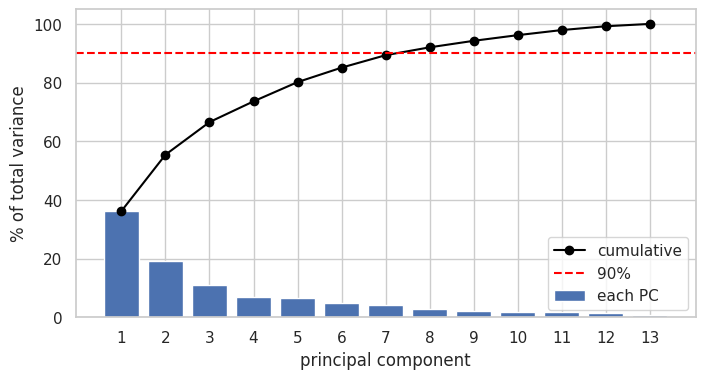

In [ ]:
k = np.arange(1, p + 1)

plt.figure(figsize=(8, 4))
plt.bar(k, 100 * explained, label="each PC")
plt.plot(k, 100 * explained.cumsum(), "o-", color="black", label="cumulative")
plt.axhline(90, color="red", ls="--", label="90%")
plt.xticks(k)
plt.xlabel("principal component")
plt.ylabel("% of total variance")
plt.legend()
plt.show()

**Reading the plot**
- PC1 alone keeps **36.2%**, and PC1 + PC2 keep **55.4%**.
- 3 PCs keep 66.5%, 5 PCs keep 80.2%, and **8 PCs keep 92.0%** (13 columns → 8 and only 8% lost).
- For a 2D picture we keep 2 PCs. We lose about 45% of the variance, but as we'll see, the important structure survives.

## 11. Step 5: Project the wines onto PC1 and PC2

Put the top 2 eigenvectors side by side in a 13 × 2 matrix $W$ and multiply:

$$T = Z\,W \qquad (178 \times 13)\cdot(13 \times 2) = (178 \times 2)$$

Each row of $T$ describes one wine with **2 numbers** (its **PC scores**) instead of 13.

In [ ]:
W = vecs[:, :2]                 # 13 x 2
T = Z.to_numpy() @ W            # 178 x 2

scores = pd.DataFrame(T, columns=["PC1", "PC2"])
scores["grape"] = y
scores.head()

,PC1,PC2,grape
0,-3.307421,-1.439402,A
1,-2.203250,0.332455,A
2,-2.509661,-1.028251,A
3,-3.746497,-2.748618,A
4,-1.006070,-0.867384,A


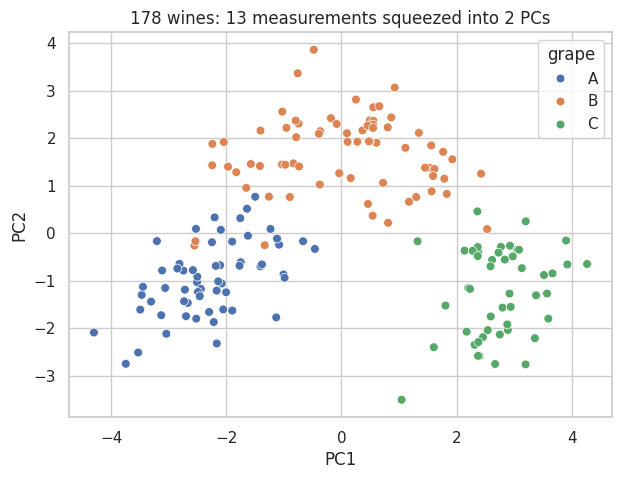

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=scores, x="PC1", y="PC2", hue="grape", s=40)
plt.title("178 wines: 13 measurements squeezed into 2 PCs")
plt.show()

**Three clear groups.** PCA never saw the grape labels, yet with only 2 numbers per wine the three grape types separate:
- along **PC1**, grape A and grape C sit at opposite ends, with B in the middle
- along **PC2**, grape B is set apart from A and C

So the 45% of variance we dropped was mostly detail. The big pattern lives in PC1 and PC2.

## 12. Check with scikit-learn

scikit-learn's `PCA` does Steps 2 to 5 in one line. Our hand-made version should give the same answer.

In [ ]:
pca = PCA(n_components=2)
T_sk = pca.fit_transform(Z)

print("Explained ratio, ours   :", explained[:2].round(4))
print("Explained ratio, sklearn:", pca.explained_variance_ratio_.round(4))
print("Same eigenvalues:           ", np.allclose(vals[:2], pca.explained_variance_))
print("Same scores (up to sign):   ", np.allclose(np.abs(T), np.abs(T_sk)))

Explained ratio, ours   : [0.362  0.1921]
Explained ratio, sklearn: [0.362  0.1921]
Same eigenvalues:            True
Same scores (up to sign):    True


In [ ]:
pd.DataFrame({"ours PC1": W[:, 0], "sklearn PC1": pca.components_[0]}, index=X.columns).round(2)

,ours PC1,sklearn PC1
alcohol,-0.14,0.14
malic_acid,0.25,-0.25
ash,0.00,-0.00
alcalinity_of_ash,0.24,-0.24
magnesium,-0.14,0.14
total_phenols,-0.39,0.39
flavanoids,-0.42,0.42
nonflavanoid_phenols,0.30,-0.30
proanthocyanins,-0.31,0.31
color_intensity,0.09,-0.09


The weights have exactly the same sizes. The only possible difference is the **sign** of a whole PC (all + become − and the other way round).

**Why?** If $C v = \lambda v$, then also $C(-v) = \lambda(-v)$. So $v$ and $-v$ lie on the **same line**, just pointing opposite ways, and different tools pick different signs.
A flipped sign only mirrors the plot: the groups, the distances and the explained variance stay exactly the same.

## 13. What do PC1 and PC2 mean? (loadings)

The entries of an eigenvector are called **loadings**: the weight each original column gets in that PC.
- big weight (either sign) → that column matters a lot for this PC
- same sign → those columns move together; opposite signs → they pull in opposite directions

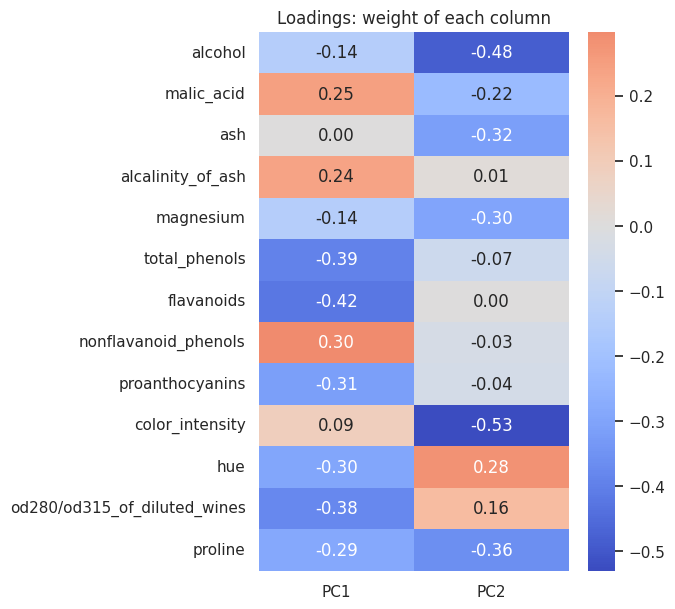

In [ ]:
loadings = pd.DataFrame(W, index=X.columns, columns=["PC1", "PC2"])

plt.figure(figsize=(5, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings: weight of each column")
plt.show()

- **PC1**: the biggest weights are `flavanoids`, `total_phenols`, `od280/od315_of_diluted_wines`, `proanthocyanins`, `hue` and `proline` on one side, against `nonflavanoid_phenols`, `malic_acid` and `alcalinity_of_ash` on the other side.
  Roughly: **"how rich in phenols and flavanoids is the wine?"**
- **PC2**: the biggest weights are `color_intensity`, `alcohol`, `proline`, `ash` and `magnesium`.
  Roughly: **"how strong and deeply coloured is the wine?"**

Let's check that against the plain averages of each grape:

In [ ]:
df.groupby("grape")[["flavanoids", "total_phenols", "color_intensity", "alcohol"]].mean().round(2)

,flavanoids,total_phenols,color_intensity,alcohol
grape,,,,
A,2.98,2.84,5.53,13.74
B,2.08,2.26,3.09,12.28
C,0.78,1.68,7.40,13.15


- Grape A is the richest in flavanoids and phenols, grape C the poorest, and B is in between: the same order we saw along **PC1**.
- Grape B has the lowest colour intensity and alcohol: that is why **PC2** sets B apart.

The PCs are weighted mixes of real measurements, and they line up with real differences between the grapes.

## 14. Conclusion

| | |
|---|---|
| **Started with** | 178 wines × 13 measurements |
| **Steps** | scale → covariance matrix → eigenvectors & eigenvalues → keep top 2 → project |
| **Kept** | 2 PCs = 55.4% of the variance (8 PCs would keep 92.0%) |
| **Result** | the 3 grape types separate clearly in 2D, although PCA never saw the labels |
| **Check** | identical to scikit-learn's `PCA` (up to sign) |

**Key ideas**
1. Always scale first, otherwise the column with the biggest units wins (unscaled, proline alone would take 99.8% of the variance).
2. Principal components are the eigenvectors of the covariance matrix; each eigenvalue is the variance along its PC.
3. PCs are ordered from most to least important, and they are uncorrelated with each other.
4. Each PC is a weighted mix of the original columns (the loadings); read its meaning from the biggest weights.

**Limits**
- PCA only finds straight-line (linear) patterns.
- PCs are mixes of columns, so they are harder to name than the original columns.
- Fewer PCs means some information is lost (45% here with 2 PCs).
- PCA ignores labels: the direction with the most variance is not guaranteed to be the one that separates the groups.